In [1]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, confusion_matrix, classification_report, f1_score,
    roc_auc_score, roc_curve
)
import pandas as pd
import numpy as np
import warnings
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.exceptions import ConvergenceWarning

from scipy.stats import kstest, norm
from scipy.optimize import OptimizeWarning

from tableone import TableOne


sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)
RANDOM_STATE = 42
pd.set_option('display.max_columns', None)

In [2]:
df_inf = pd.read_csv('PCOS_infertility.csv')
df_woinf = pd.read_excel('PCOS_data_without_infertility.xlsx', sheet_name='Full_new')
df = pd.merge(df_woinf, df_inf, on='Patient File No.', suffixes=('','_y'),how='left')
df = df.drop(['Unnamed: 44', 'Sl. No_y', 'PCOS (Y/N)_y', '  I   beta-HCG(mIU/mL)_y',
       'II    beta-HCG(mIU/mL)_y', 'AMH(ng/mL)_y', 'Sl. No'], axis=1)

df = df.set_index('Patient File No.')
target = 'PCOS (Y/N)'
predictors = df.columns.tolist()[1:] # all except PCOS (Y/N)

display(df.info())

<class 'pandas.core.frame.DataFrame'>
Index: 541 entries, 1 to 541
Data columns (total 42 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   PCOS (Y/N)              541 non-null    int64  
 1    Age (yrs)              541 non-null    int64  
 2   Weight (Kg)             541 non-null    float64
 3   Height(Cm)              541 non-null    float64
 4   BMI                     541 non-null    float64
 5   Blood Group             541 non-null    int64  
 6   Pulse rate(bpm)         541 non-null    int64  
 7   RR (breaths/min)        541 non-null    int64  
 8   Hb(g/dl)                541 non-null    float64
 9   Cycle(R/I)              541 non-null    int64  
 10  Cycle length(days)      541 non-null    int64  
 11  Marraige Status (Yrs)   540 non-null    float64
 12  Pregnant(Y/N)           541 non-null    int64  
 13  No. of aborptions       541 non-null    int64  
 14    I   beta-HCG(mIU/mL)  541 non-null    float64

None

**Ugotovitev**: dva faktorja sta tipa `str` in ju moramo pretvorit v numerično obliko, pravilno moramo enkodirati `Cycle (R/I)` in `Blood Group`, nato bomo izrisali *Table one*.

In [3]:
df['AMH(ng/mL)'] = pd.to_numeric(df['AMH(ng/mL)'], errors='coerce')
df['II    beta-HCG(mIU/mL)'] = pd.to_numeric(df['II    beta-HCG(mIU/mL)'], errors='coerce')

cycle = {2: 0, 4: 1, 5: np.nan}
df['Cycle(R/I)'] = df['Cycle(R/I)'].replace(cycle)

display(df.head())

,PCOS (Y/N),Age (yrs),Weight (Kg),Height(Cm),BMI,Blood Group,Pulse rate(bpm),RR (breaths/min),Hb(g/dl),Cycle(R/I),Cycle length(days),Marraige Status (Yrs),Pregnant(Y/N),No. of aborptions,I beta-HCG(mIU/mL),II beta-HCG(mIU/mL),FSH(mIU/mL),LH(mIU/mL),FSH/LH,Hip(inch),Waist(inch),Waist:Hip Ratio,TSH (mIU/L),AMH(ng/mL),PRL(ng/mL),Vit D3 (ng/mL),PRG(ng/mL),RBS(mg/dl),Weight gain(Y/N),hair growth(Y/N),Skin darkening (Y/N),Hair loss(Y/N),Pimples(Y/N),Fast food (Y/N),Reg.Exercise(Y/N),BP _Systolic (mmHg),BP _Diastolic (mmHg),Follicle No. (L),Follicle No. (R),Avg. F size (L) (mm),Avg. F size (R) (mm),Endometrium (mm)
Patient File No.,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
1,0,28,44.6,152.0,19.300000,15,78,22,10.48,0.0,5,7.0,0,0,1.99,1.99,7.95,3.68,2.160326,36,30,0.833333,0.68,2.07,45.16,17.1,0.57,92.0,0,0,0,0,0,1.0,0,110,80,3,3,18.0,18.0,8.5
2,0,36,65.0,161.5,24.921163,15,74,20,11.70,0.0,5,11.0,1,0,60.80,1.99,6.73,1.09,6.174312,38,32,0.842105,3.16,1.53,20.09,61.3,0.97,92.0,0,0,0,0,0,0.0,0,120,70,3,5,15.0,14.0,3.7
3,1,33,68.8,165.0,25.270891,11,72,18,11.80,0.0,5,10.0,1,0,494.08,494.08,5.54,0.88,6.295455,40,36,0.900000,2.54,6.63,10.52,49.7,0.36,84.0,0,0,0,1,1,1.0,0,120,80,13,15,18.0,20.0,10.0
4,0,37,65.0,148.0,29.674945,13,72,20,12.00,0.0,5,4.0,0,0,1.99,1.99,8.06,2.36,3.415254,42,36,0.857143,16.41,1.22,36.90,33.4,0.36,76.0,0,0,0,0,0,0.0,0,120,70,2,2,15.0,14.0,7.5
5,0,25,52.0,161.0,20.060954,11,72,18,10.00,0.0,5,1.0,1,0,801.45,801.45,3.98,0.90,4.422222,37,30,0.810811,3.57,2.26,30.09,43.8,0.38,84.0,0,0,0,1,0,0.0,0,120,80,3,4,16.0,14.0,7.0


In [4]:
categorical = ['Blood Group', 'Cycle(R/I)', 'Pregnant(Y/N)', 'Weight gain(Y/N)', 'hair growth(Y/N)', 'Skin darkening (Y/N)', 
               'Hair loss(Y/N)', 'Pimples(Y/N)', 'Fast food (Y/N)', 'Reg.Exercise(Y/N)']

continuous = [' Age (yrs)', 'Weight (Kg)', 'Height(Cm) ', 'BMI', 'Pulse rate(bpm) ', 
              'RR (breaths/min)', 'Hb(g/dl)', 'Cycle length(days)', 'Marraige Status (Yrs)', 
              'No. of aborptions', '  I   beta-HCG(mIU/mL)', 'II    beta-HCG(mIU/mL)', 
              'FSH(mIU/mL)', 'LH(mIU/mL)', 'FSH/LH', 'Hip(inch)', 'Waist(inch)', 
              'Waist:Hip Ratio', 'TSH (mIU/L)', 'AMH(ng/mL)', 'PRL(ng/mL)', 
              'Vit D3 (ng/mL)', 'PRG(ng/mL)', 'RBS(mg/dl)', 'BP _Systolic (mmHg)',
              'BP _Diastolic (mmHg)', 'Follicle No. (L)', 'Follicle No. (R)',
              'Avg. F size (L) (mm)', 'Avg. F size (R) (mm)', 'Endometrium (mm)']
non_normal = []
for c in continuous:
    stat, p = kstest(df[c], 'norm')
    if p < 0.05:
        non_normal.append(c)
        
print(f'Število kategoričnih faktorjev: {len(categorical)}',
      f'\nŠtevilo numeričnih faktorjev: {len(continuous)}')



table = TableOne(
    data=df,
    columns=continuous + categorical,
    categorical=categorical,
    groupby=target,
    nonnormal=non_normal, 
    pval=True,
    overall=False,
    missing=True,
    htest_name=True
)

print(table.tabulate(tablefmt="fancy_grid"))
table.tableone.to_csv("PCOS_table_one_tableone.csv")

Število kategoričnih faktorjev: 10 
Število numeričnih faktorjev: 31
╒══════════════════════════════════════╤══════╤═══════════╤═════════════════════╤═════════════════════╤═══════════╤═══════════════════════════════════════════╕
│                                      │      │ Missing   │ 0                   │ 1                   │ P-Value   │ Test                                      │
╞══════════════════════════════════════╪══════╪═══════════╪═════════════════════╪═════════════════════╪═══════════╪═══════════════════════════════════════════╡
│ n                                    │      │           │ 364                 │ 177                 │           │                                           │
├──────────────────────────────────────┼──────┼───────────┼─────────────────────┼─────────────────────┼───────────┼───────────────────────────────────────────┤
│ Age (yrs), median [Q1,Q3]            │      │ 0         │ 32.0 [28.0,36.0]    │ 29.0 [27.0,33.0]    │ <0.001    │ Kruskal-Wallis 

╒══════════════════════════════════════╤══════╤═══════════╤═════════════════════╤═════════════════════╤═══════════╤═══════════════════════════════════════════╕
│                                      │      │ Missing   │ 0                   │ 1                   │ P-Value   │ Test                                      │
╞══════════════════════════════════════╪══════╪═══════════╪═════════════════════╪═════════════════════╪═══════════╪═══════════════════════════════════════════╡
│ n                                    │      │           │ 364                 │ 177                 │           │                                           │
├──────────────────────────────────────┼──────┼───────────┼─────────────────────┼─────────────────────┼───────────┼───────────────────────────────────────────┤
│ Age (yrs), median [Q1,Q3]            │      │ 0         │ 32.0 [28.0,36.0]    │ 29.0 [27.0,33.0]    │ <0.001    │ Kruskal-Wallis                            │
├──────────────────────────────────────┼

**Komentar**: Iz tabele 1 je razvidno kateri faktorji so statistično značilno različni med skupinama (PCOS/no PCOS). Tabela nam torej da začetni vpogled kateri faktorji bi lahko imeli večjo napovedno vrednost (p < 0.05): *Age, weight, BMI, pulse rate, Hb, cycle length, marriage status, FSH, FSH/L2, Hip, Waist, AMH, Follicle No. (leva in desna), Avg. Follicle Size (leva in desna), Endometrium, Cycle regularity, weight gain, hair growth, skin darkening, hair loss, pimples, fast food*.

**Naslednji korak**: Iskanje faktorjev tveganja (univariatna LOGREG --> multipla LOGREG --> regularizacija)

In [6]:
def fit_sklearn_logistic_with_wald_inference(X, y):
    X_array = np.asarray(X, dtype=float)
    y_array = np.asarray(y, dtype=int)
    if X_array.ndim == 1:
        X_array = X_array.reshape(-1, 1)

    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X_array)
    model = LogisticRegression(
        penalty=None, solver='lbfgs', max_iter=10000,
        random_state=RANDOM_STATE
    )
    with warnings.catch_warnings():
        warnings.simplefilter('ignore', ConvergenceWarning)
        warnings.simplefilter('ignore', OptimizeWarning)
        model.fit(X_scaled, y_array)

    probability = model.predict_proba(X_scaled)[:, 1]
    design_scaled = np.column_stack([np.ones(len(X_scaled)), X_scaled])
    weights = np.clip(
        probability * (1 - probability), np.finfo(float).eps, None
    )
    fisher_information = design_scaled.T @ (design_scaled * weights[:, None])
    covariance_scaled = np.linalg.pinv(fisher_information)
    parameters_scaled = np.concatenate([model.intercept_, model.coef_[0]])

    # Transform intercept and slopes from standardized to original units.
    transformation = np.zeros((X_array.shape[1] + 1, X_array.shape[1] + 1))
    transformation[0, 0] = 1.0
    transformation[0, 1:] = -scaler.mean_ / scaler.scale_
    transformation[1:, 1:] = np.diag(1.0 / scaler.scale_)
    parameters = transformation @ parameters_scaled
    covariance = transformation @ covariance_scaled @ transformation.T

    standard_errors = np.sqrt(np.clip(np.diag(covariance), 0, None))
    z_statistics = np.divide(
        parameters, standard_errors,
        out=np.full_like(parameters, np.nan), where=standard_errors > 0
    )
    p_values = 2 * norm.sf(np.abs(z_statistics))
    critical_value = norm.ppf(0.975)

    return {
        'model': model,
        'scaler': scaler,
        'coefficients': parameters,
        'standard_errors': standard_errors,
        'p_values': p_values,
        'ci_lower': parameters - critical_value * standard_errors,
        'ci_upper': parameters + critical_value * standard_errors,
        'information_rank': np.linalg.matrix_rank(fisher_information),
    }


def univariable_logistic_regression(df, target, predictors):
    results = []

    for predictor in predictors:
        data = df[[target, predictor]].copy()
        data[predictor] = pd.to_numeric(data[predictor], errors='coerce')
        data = data.dropna()

        if data[predictor].nunique() < 2 or data[target].nunique() < 2:
            print(f'Did not check {predictor}: insufficient variation')
            continue

        try:
            fitted = fit_sklearn_logistic_with_wald_inference(
                data[[predictor]], data[target]
            )
            beta = fitted['coefficients'][1]
            results.append({
                'Variable': predictor,
                'OR': np.exp(beta),
                'CI_lower': np.exp(fitted['ci_lower'][1]),
                'CI_upper': np.exp(fitted['ci_upper'][1]),
                'p_value': fitted['p_values'][1],
                'N': len(data),
            })
        except Exception as error:
            print(f'Model failed for {predictor}: {error}')

    return pd.DataFrame(results)


results = univariable_logistic_regression(df, target, predictors)
results = results.sort_values('p_value').reset_index(drop=True)
print(results.round(3))

                  Variable     OR  CI_lower  CI_upper  p_value    N
0         Follicle No. (R)  1.607     1.483     1.742    0.000  541
1         Follicle No. (L)  1.536     1.425     1.655    0.000  541
2     Skin darkening (Y/N)  9.028     5.954    13.690    0.000  541
3         hair growth(Y/N)  8.970     5.852    13.750    0.000  541
4         Weight gain(Y/N)  7.312     4.899    10.912    0.000  541
5               Cycle(R/I)  6.305     4.181     9.509    0.000  540
6          Fast food (Y/N)  5.892     3.885     8.936    0.000  540
7             Pimples(Y/N)  3.561     2.428     5.223    0.000  541
8               AMH(ng/mL)  1.110     1.071     1.150    0.000  540
9              Weight (Kg)  1.043     1.025     1.061    0.000  541
10                     BMI  1.114     1.063     1.168    0.000  541
11      Cycle length(days)  0.751     0.654     0.862    0.000  541
12          Hair loss(Y/N)  2.103     1.460     3.028    0.000  541
13               Age (yrs)  0.933     0.900     

In [8]:
UNIVARIABLE_P_THRESHOLD = 0.10
selected_factors = (
    results.loc[results['p_value'] < UNIVARIABLE_P_THRESHOLD, 'Variable']
    .tolist()
)

display(
    results.loc[results['Variable'].isin(selected_factors),
                ['Variable', 'OR', 'CI_lower', 'CI_upper', 'p_value', 'N']]
    .reset_index(drop=True)
    .round(4)
)

,Variable,OR,CI_lower,CI_upper,p_value,N
0,Follicle No. (R),1.6075,1.4833,1.7420,0.0000,541
1,Follicle No. (L),1.5358,1.4250,1.6551,0.0000,541
2,Skin darkening (Y/N),9.0283,5.9539,13.6903,0.0000,541
3,hair growth(Y/N),8.9700,5.8517,13.7501,0.0000,541
4,Weight gain(Y/N),7.3117,4.8993,10.9119,0.0000,541
5,Cycle(R/I),6.3051,4.1809,9.5085,0.0000,540
6,Fast food (Y/N),5.8917,3.8847,8.9356,0.0000,540
7,Pimples(Y/N),3.5610,2.4278,5.2231,0.0000,541
8,AMH(ng/mL),1.1100,1.0712,1.1503,0.0000,540
9,Weight (Kg),1.0429,1.0251,1.0610,0.0000,541


**Komentar**: Za potencialne faktorje smo vzeli vse, za katere velja `p < 0.10`. Če primerjamo te rezultate s *Table one* lahko vidimo, da je večina faktorjev, ki so bili izpostavljeni v tabeli statistično značilni tudi pri univariatni logistični regresiji; razlikujejo se le v naslednjih faktorjih: FSH, FSH/LH ter LH. Število faktorjev smo v tem koraku zmanjšali iz 41 na 23.

**Multipla logistična regresija**

In [9]:
multivariable_data = df[[target] + selected_factors].copy()
multivariable_data = multivariable_data.apply(pd.to_numeric, errors='coerce').dropna()

y_mv = multivariable_data[target].astype(int)
X_mv = multivariable_data[selected_factors]
multivariable_inference = fit_sklearn_logistic_with_wald_inference(X_mv, y_mv)
multivariable_model = multivariable_inference['model']
multivariable_scaler = multivariable_inference['scaler']

multivariable_results = pd.DataFrame({
    'Variable': selected_factors,
    'OR': np.exp(multivariable_inference['coefficients'][1:]),
    'CI_lower': np.exp(multivariable_inference['ci_lower'][1:]),
    'CI_upper': np.exp(multivariable_inference['ci_upper'][1:]),
    'p_value': multivariable_inference['p_values'][1:],
    'N': len(multivariable_data),
}).sort_values('p_value').reset_index(drop=True)

multivariable_results['Variable'] = multivariable_results['Variable'].str.strip()
multivariable_results['OR (95% CI)'] = multivariable_results.apply(
    lambda row: f"{row['OR']:.3f} ({row['CI_lower']:.3f} to {row['CI_upper']:.3f})", axis=1
)
multivariable_table = multivariable_results[['Variable', 'OR (95% CI)', 'p_value', 'N']].copy()
multivariable_table['p_value'] = multivariable_table['p_value'].map(lambda value: f'{value:.4f}')

print(f'Multivariable model: N = {len(multivariable_data)}, '
      f'events = {int(y_mv.sum())}, factors = {len(selected_factors)}')
display(multivariable_table)
multivariable_results.to_csv('PCOS_multivariable_logistic_regression.csv', index=False)

Multivariable model: N = 537, events = 175, factors = 23


,Variable,OR (95% CI),p_value,N
0,Follicle No. (R),1.608 (1.390 to 1.860),0.0000,537
1,hair growth(Y/N),5.383 (2.313 to 12.528),0.0001,537
2,Skin darkening (Y/N),4.141 (1.835 to 9.344),0.0006,537
3,Weight gain(Y/N),4.552 (1.896 to 10.931),0.0007,537
4,Cycle(R/I),3.731 (1.634 to 8.519),0.0018,537
5,Pimples(Y/N),2.928 (1.360 to 6.304),0.0060,537
6,Pulse rate(bpm),1.126 (0.982 to 1.291),0.0904,537
7,Marraige Status (Yrs),0.913 (0.818 to 1.020),0.1071,537
8,Follicle No. (L),1.105 (0.960 to 1.273),0.1649,537
9,Endometrium (mm),1.118 (0.937 to 1.333),0.2145,537


The adjusted estimates above may become unstable when correlated measurements (for example left/right follicle counts and anthropometric measures) are entered together. Elastic Net is useful here because it combines L1 shrinkage/selection with L2 stabilization.

## Elastic Net logistic regression

The penalty strength (`C`) and L1/L2 mixing parameter (`l1_ratio`) are selected by stratified 10-fold cross-validation in the training set using ROC AUC. A stratified 25% hold-out set provides a simple performance check. The final coefficient model is then refitted to all observations with the selected hyperparameters. Because the requested univariable screen was performed before the split, both AUC estimates are exploratory and may be optimistic; an unbiased estimate would repeat the complete screening and tuning workflow inside an outer resampling loop or use a genuinely external validation cohort.

In [8]:
from sklearn.base import clone
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import StratifiedKFold
from sklearn.exceptions import ConvergenceWarning
import warnings

X_en = df[selected_factors].apply(pd.to_numeric, errors='coerce')
y_en = df[target].astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X_en, y_en, test_size=0.25, stratify=y_en, random_state=RANDOM_STATE
)

elastic_net_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
    ('model', LogisticRegression(
        penalty='elasticnet', solver='saga', max_iter=20000,
        random_state=RANDOM_STATE
    )),
])

inner_cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=RANDOM_STATE)
parameter_grid = {
    'model__C': np.logspace(-3, 2, 20),
    # Values above zero ensure that every candidate is an Elastic Net model
    # with an L1 component capable of setting coefficients exactly to zero.
    'model__l1_ratio': [0.10, 0.25, 0.50, 0.75, 0.90, 1.00],
}

elastic_net_search = GridSearchCV(
    elastic_net_pipeline, parameter_grid, scoring='roc_auc',
    cv=inner_cv, n_jobs=1, refit=True
)
with warnings.catch_warnings():
    warnings.simplefilter('ignore', ConvergenceWarning)
    elastic_net_search.fit(X_train, y_train)

test_probability = elastic_net_search.predict_proba(X_test)[:, 1]
test_auc = roc_auc_score(y_test, test_probability)

print(f"Best C: {elastic_net_search.best_params_['model__C']:.5g}")
print(f"Best l1_ratio: {elastic_net_search.best_params_['model__l1_ratio']:.2f}")
print(f'Best training CV ROC AUC: {elastic_net_search.best_score_:.3f}')
print(f'Hold-out ROC AUC: {test_auc:.3f}')

# Refit the selected specification to all observations for the final factor list.
final_elastic_net = clone(elastic_net_search.best_estimator_)
with warnings.catch_warnings():
    warnings.simplefilter('ignore', ConvergenceWarning)
    final_elastic_net.fit(X_en, y_en)

Best C: 0.020691
Best l1_ratio: 0.25
Best training CV ROC AUC: 0.954
Hold-out ROC AUC: 0.956


### Bootstrap stability and confidence intervals

Classical p-values are not reported for Elastic Net coefficients because the shrinkage and data-driven selection invalidate ordinary logistic-regression inference. Instead, the following cell reports how often each factor is retained in 500 stratified bootstrap samples and percentile bootstrap 95% intervals. Continuous-factor odds ratios are per 1 SD increase; binary-factor odds ratios compare 1 versus 0. These intervals describe stability and should not be interpreted as post-selection hypothesis tests.

In [9]:
N_BOOTSTRAPS = 500
COEFFICIENT_ZERO_TOLERANCE = 1e-8
STABILITY_THRESHOLD = 0.50

feature_names = np.asarray(selected_factors)
binary_factor = X_en.nunique(dropna=True).eq(2).to_numpy()
final_coefficients = final_elastic_net.named_steps['model'].coef_[0]
final_scales = final_elastic_net.named_steps['scaler'].scale_

# For binary factors convert the standardized coefficient to the 0-to-1 contrast.
# Continuous factors remain on a 1-SD scale so their magnitudes are comparable.
final_log_or = np.where(binary_factor, final_coefficients / final_scales, final_coefficients)

rng = np.random.default_rng(RANDOM_STATE)
bootstrap_log_or = np.full((N_BOOTSTRAPS, len(feature_names)), np.nan)
bootstrap_selected = np.zeros((N_BOOTSTRAPS, len(feature_names)), dtype=bool)
class_indices = {level: np.flatnonzero(y_en.to_numpy() == level) for level in np.sort(y_en.unique())}

with warnings.catch_warnings():
    warnings.simplefilter('ignore', ConvergenceWarning)
    for bootstrap_number in range(N_BOOTSTRAPS):
        sample_indices = np.concatenate([
            rng.choice(indices, size=len(indices), replace=True)
            for indices in class_indices.values()
        ])
        rng.shuffle(sample_indices)

        bootstrap_model = clone(final_elastic_net)
        bootstrap_model.fit(X_en.iloc[sample_indices], y_en.iloc[sample_indices])
        coefficients = bootstrap_model.named_steps['model'].coef_[0]
        scales = bootstrap_model.named_steps['scaler'].scale_

        bootstrap_log_or[bootstrap_number] = np.where(
            binary_factor, coefficients / scales, coefficients
        )
        bootstrap_selected[bootstrap_number] = (
            np.abs(coefficients) > COEFFICIENT_ZERO_TOLERANCE
        )

lower_log_or, upper_log_or = np.percentile(bootstrap_log_or, [2.5, 97.5], axis=0)
selection_frequency = bootstrap_selected.mean(axis=0)
selected_in_final_model = np.abs(final_coefficients) > COEFFICIENT_ZERO_TOLERANCE

elastic_net_results = pd.DataFrame({
    'Variable': pd.Series(feature_names).str.strip(),
    'Contrast': np.where(binary_factor, '1 vs 0', 'per 1 SD'),
    'Standardized_coefficient': final_coefficients,
    'OR': np.exp(final_log_or),
    'CI_lower': np.exp(lower_log_or),
    'CI_upper': np.exp(upper_log_or),
    'Selection_frequency': selection_frequency,
    'Selected_final_model': selected_in_final_model,
})
elastic_net_results['Absolute_standardized_coefficient'] = (
    elastic_net_results['Standardized_coefficient'].abs()
)
elastic_net_results = elastic_net_results.sort_values(
    ['Selected_final_model', 'Absolute_standardized_coefficient'], ascending=[False, False]
).reset_index(drop=True)

most_predictive_factors = elastic_net_results.loc[
    elastic_net_results['Selected_final_model']
    & (elastic_net_results['Selection_frequency'] >= STABILITY_THRESHOLD)
].copy()
if most_predictive_factors.empty:
    most_predictive_factors = elastic_net_results.loc[
        elastic_net_results['Selected_final_model']
    ].copy()

most_predictive_factors['OR (bootstrap 95% CI)'] = most_predictive_factors.apply(
    lambda row: f"{row['OR']:.3f} ({row['CI_lower']:.3f} to {row['CI_upper']:.3f})", axis=1
)
most_predictive_table = most_predictive_factors[[
    'Variable', 'Contrast', 'OR (bootstrap 95% CI)', 'Selection_frequency'
]].copy()
most_predictive_table['Selection_frequency'] = (
    100 * most_predictive_table['Selection_frequency']
).map(lambda value: f'{value:.1f}%')

print(f'{selected_in_final_model.sum()} of {len(feature_names)} screened factors have non-zero '
      'coefficients in the final Elastic Net model.')
print(f'{len(most_predictive_factors)} factors were retained in at least '
      f'{STABILITY_THRESHOLD:.0%} of bootstrap samples:')
display(most_predictive_table)
elastic_net_results.to_csv('PCOS_elastic_net_all_coefficients.csv', index=False)
most_predictive_factors.to_csv('PCOS_elastic_net_predictive_factors.csv', index=False)

13 of 23 screened factors have non-zero coefficients in the final Elastic Net model.
13 factors were retained in at least 50% of bootstrap samples:


,Variable,Contrast,OR (bootstrap 95% CI),Selection_frequency
0,Follicle No. (R),per 1 SD,1.967 (1.754 to 2.214),100.0%
1,Follicle No. (L),per 1 SD,1.553 (1.385 to 1.740),100.0%
2,hair growth(Y/N),1 vs 0,2.074 (1.583 to 2.654),100.0%
3,Skin darkening (Y/N),1 vs 0,1.986 (1.546 to 2.531),100.0%
4,Weight gain(Y/N),1 vs 0,1.897 (1.524 to 2.443),100.0%
5,Cycle(R/I),1 vs 0,1.793 (1.353 to 2.313),100.0%
6,Fast food (Y/N),1 vs 0,1.381 (1.086 to 1.821),99.2%
7,Pimples(Y/N),1 vs 0,1.357 (1.053 to 1.720),99.2%
8,AMH(ng/mL),per 1 SD,1.093 (1.000 to 1.198),93.8%
9,Age (yrs),per 1 SD,0.942 (0.850 to 1.000),84.8%


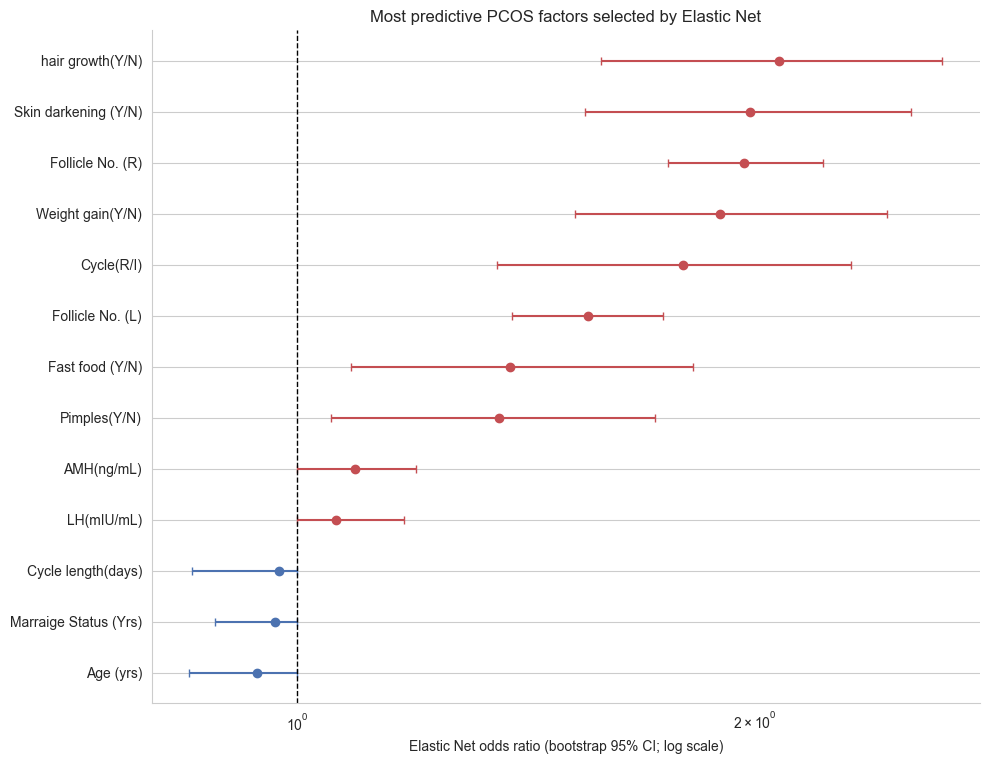

In [10]:
forest_data = most_predictive_factors.sort_values('OR').reset_index(drop=True)
figure_height = max(5, 0.48 * len(forest_data) + 1.5)
fig, ax = plt.subplots(figsize=(10, figure_height))

for row_number, row in forest_data.iterrows():
    color = '#C44E52' if row['OR'] >= 1 else '#4C72B0'
    ax.errorbar(
        row['OR'], row_number,
        xerr=[[row['OR'] - row['CI_lower']], [row['CI_upper'] - row['OR']]],
        fmt='o', color=color, ecolor=color, capsize=3, markersize=6
    )

ax.axvline(1, color='black', linestyle='--', linewidth=1)
ax.set_xscale('log')
ax.set_yticks(range(len(forest_data)))
ax.set_yticklabels(forest_data['Variable'])
ax.set_xlabel('Elastic Net odds ratio (bootstrap 95% CI; log scale)')
ax.set_ylabel('')
ax.set_title('Most predictive PCOS factors selected by Elastic Net')
ax.grid(axis='x', alpha=0.25)
sns.despine(ax=ax)
plt.tight_layout()
plt.savefig('PCOS_elastic_net_forest_plot.png', dpi=300, bbox_inches='tight')
plt.show()